In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import math as math
import seaborn as sns

In [3]:
songs_df = pd.read_csv('C:\\Users\\nikki\\Desktop\\praca IT\\Portfolio\\Python\\DataSet_Eurovision\\song_data.csv', encoding='latin-1')
country_df = pd.read_csv('C:\\Users\\nikki\\Desktop\\praca IT\\Portfolio\\Python\\DataSet_Eurovision\\country_data.csv', encoding='latin-1')


In [4]:
songs_df = songs_df.replace('unknown', np.nan)

In [5]:
songs_df = songs_df.drop(['direct_qualifier_10', 'age', 'selection', 'release_date', 'key_change_10', 'race', 'semi_final'], axis=1)

In [6]:
songs_df = songs_df.merge(country_df, how = 'left', on='country')

In [7]:
finalists = songs_df[songs_df['qualified_10'] != '0']

In [8]:
finalists = finalists.drop(['semi_draw_position', 'qualified_10', 'semi_place', 'semi_televote_points','semi_jury_points', 'semi_total_points'], axis=1)

In [21]:
print("Które kraje osiągają najlepsze wyniki w konkursie Eurowizji?")
countries = finalists.groupby(['country', 'region']).agg({'country': 'count',
'final_place': 'mean',
'final_total_points': 'mean',
'final_televote_points': 'mean', 
'final_jury_points': 'mean'})
countries.columns = [
    'Liczba wystąpień',
    'Średnie miejsce',
    'Średnie punkty',
    'Średnie punkty televizyjne',
    'Średnie punkty jury']
display(countries.sort_values('Średnie miejsce').round(2).head(10))
print('A które kraje osiągają najgorsze wyniki w konkursie Eurowizji?')
display(countries.sort_values('Średnie miejsce', ascending=False).round(2).head(10))

Które kraje osiągają najlepsze wyniki w konkursie Eurowizji?


,,Liczba wystąpień,Średnie miejsce,Średnie punkty,Średnie punkty televizyjne,Średnie punkty jury
country,region,,,,,
Turkey,Eastern Europe,3,4.33,279.67,185.33,94.33
Sweden,Scandanavia,13,6.46,337.85,170.00,196.00
Italy,Western Europe,12,6.83,294.08,155.36,165.45
Russia,Eastern Europe,10,6.90,272.30,188.44,114.11
Bulgaria,Eastern Europe,4,7.75,314.50,153.25,161.25
Ukraine,Eastern Europe,12,8.67,244.17,163.82,102.55
Netherlands,Western Europe,8,9.25,139.50,64.83,119.17
North Macedonia,Eastern Europe,2,10.00,152.50,58.00,247.00
Belgium,Western Europe,8,10.12,187.62,90.14,124.29


A które kraje osiągają najgorsze wyniki w konkursie Eurowizji?


,,Liczba wystąpień,Średnie miejsce,Średnie punkty,Średnie punkty televizyjne,Średnie punkty jury
country,region,,,,,
San Marino,Western Europe,3,21.50,54.00,31.33,21.33
Belarus,Eastern Europe,5,19.40,52.00,28.50,36.50
United Kingdom,Western Europe,14,19.14,100.64,50.67,66.75
Spain,Western Europe,14,18.93,100.86,51.54,57.08
Germany,Western Europe,14,18.64,105.79,57.62,56.31
Ireland,Western Europe,5,18.40,107.20,66.75,67.25
Slovenia,Eastern Europe,6,18.33,90.83,37.17,53.67
Croatia,Eastern Europe,3,18.00,104.67,63.67,41.00
Finland,Scandanavia,8,16.88,153.12,119.14,55.86


<Axes: xlabel='Średnie punkty', ylabel='country'>

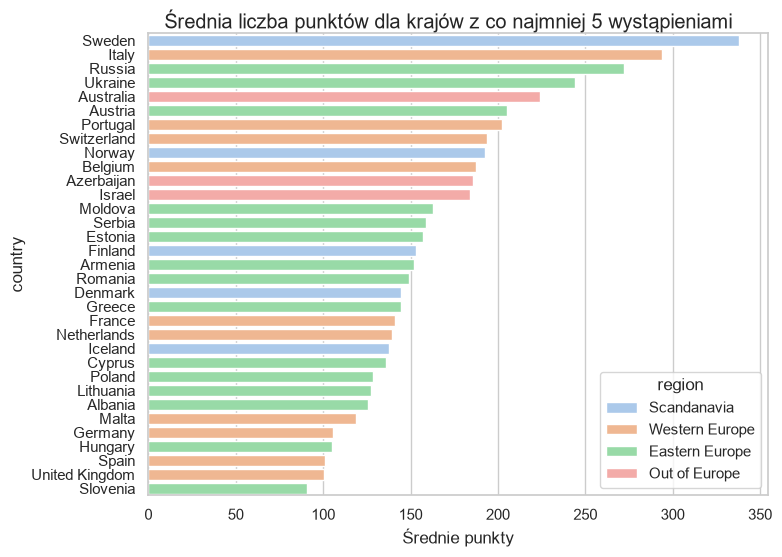

In [22]:
plt.figure(figsize=(8,6))
sns.set_theme(style = 'whitegrid')
plt.suptitle('Średnia liczba punktów dla krajów z co najmniej 5 wystąpieniami', y = 0.92)

sns.barplot(data = countries[countries['Liczba wystąpień'] > 5].sort_values('Średnie punkty', 
                                                                          ascending = False), 
           x = 'Średnie punkty', y = 'country', hue = 'region', dodge = False, palette = 'pastel')

In [23]:
print('Jakie są różnice w punktacji między regionami?')
regions = finalists.groupby(['region'])[['final_place', 'final_total_points']].mean()
regions.columns = ['Średnie miejsce', 'Średnie punkty']
regions.sort_values('Średnie miejsce').round(2)

Jakie są różnice w punktacji między regionami?


,Średnie miejsce,Średnie punkty
region,,
Scandanavia,11.44,206.62
Out of Europe,11.62,185.88
Eastern Europe,13.16,159.36
Western Europe,15.13,148.46


Czy gatunek muzyki ma wpływ na wyniki w konkursie Eurowizji?


<Axes: ylabel='final_total_points'>

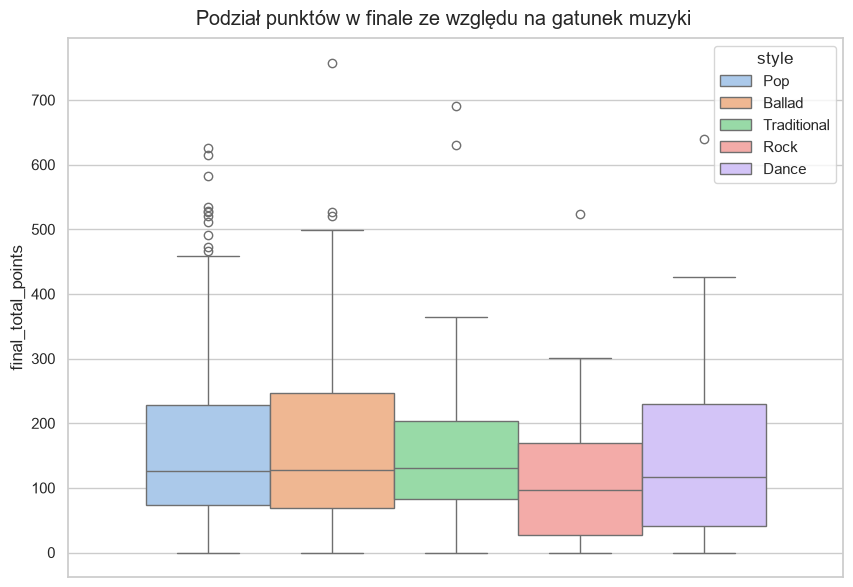

In [24]:
print('Czy gatunek muzyki ma wpływ na wyniki w konkursie Eurowizji?')
plt.figure(figsize=(10,7))
plt.suptitle('Podział punktów w finale ze względu na gatunek muzyki', y = 0.92)
sns.boxplot(data = finalists[finalists['style'] != 'Opera'], 
            hue = 'style', y = 'final_total_points', palette = 'pastel')

In [25]:
genres = finalists.groupby(['style']).agg({'style': 'count', 
                                           'final_place': 'mean', 
                                           'final_jury_points': 'mean', 
                                          'final_televote_points': 'mean', 
                                           'final_total_points': 'mean'})

genres.columns = ['N', 'Średnie finałowe miejsce', 'Średnie punkty jury', 'Średnie punkty televizji', 'Średnie punkty całkowite']
genres['Różnica punktów'] = genres['Średnie punkty jury'] - genres['Średnie punkty televizji']
genres.sort_values('Średnie finałowe miejsce').round(2)

,N,Średnie finałowe miejsce,Średnie punkty jury,Średnie punkty televizji,Średnie punkty całkowite,Różnica punktów
style,,,,,,
Opera,3,10.00,107.00,112.00,219.00,-5.00
Ballad,98,12.66,107.24,80.04,172.12,27.20
Traditional,29,12.86,71.69,117.54,169.66,-45.85
Pop,163,13.44,91.64,88.27,168.69,3.38
Dance,39,14.05,67.09,113.79,155.76,-46.70
Rock,27,15.74,74.29,78.14,118.56,-3.86


<Axes: ylabel='Różnica punktów'>

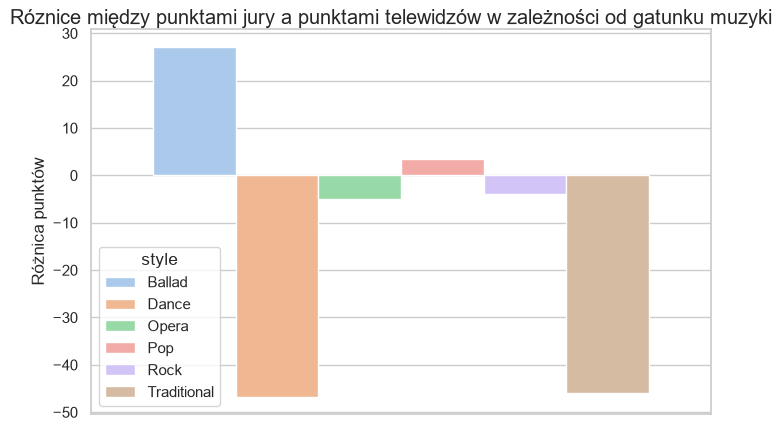

In [40]:
plt.figure(figsize=(8,5))
plt.suptitle('Róznice między punktami jury a punktami telewidzów w zależności od gatunku muzyki', y = 0.92)
sns.barplot(data = genres.reset_index(), hue = 'style', y = 'Różnica punktów', palette = 'pastel')

In [11]:
def language(x):
    if x == 'English': return 'English'
    elif x.find(',') > 0: return 'Mixed' #if there is a comma it means that more than 1 language was used in a song
    else: return 'Native'

In [12]:
finalists['language2'] = finalists['language'].apply(language)

<Axes: ylabel='final_total_points'>

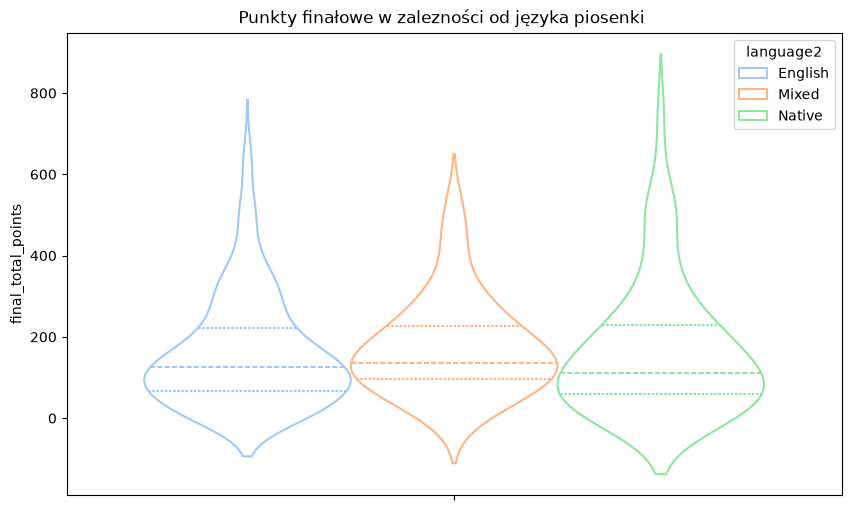

In [14]:
plt.figure(figsize = (10,6))
plt.suptitle('Punkty finałowe w zalezności od języka piosenki', y = 0.92)
sns.violinplot(data = finalists, hue= 'language2', y = 'final_total_points', inner='quart', fill=False, palette = 'pastel')

In [37]:
languages = finalists.groupby(['language2']).agg({'language2': 'count', 
                                                  'final_place': 'mean', 
                                                  'final_televote_points': 'mean',
                                                 'final_jury_points': 'mean', 
                                                  'final_total_points': 'mean'})

languages.columns = ['N', 'Średnie miejsce', 'Średnie punkty telewidzów', 'Średnie punkty jury', 'Średnie punkty całkowite']
languages['Różnica punktów jury i telewidzów'] = languages['Średnie punkty jury'] - languages['Średnie punkty telewidzów']
languages.sort_values('Średnie miejsce').round(2)

,N,Średnie miejsce,Średnie punkty telewidzów,Średnie punkty jury,Średnie punkty całkowite,Różnica punktów jury i telewidzów
language2,,,,,,
Mixed,39,12.74,94.41,80.31,175.03,-14.10
English,243,13.41,86.01,93.17,162.54,7.15
Native,77,13.65,102.90,89.58,167.48,-13.31


<Axes: ylabel='Różnica punktów jury i telewidzów'>

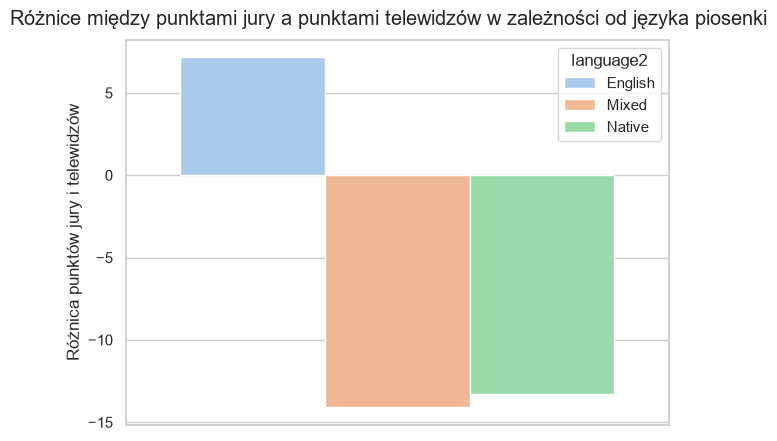

In [41]:
plt.figure(figsize=(7,5))
plt.suptitle('Różnice między punktami jury a punktami telewidzów w zależności od języka piosenki', 
             y = 0.94)

sns.barplot(data = languages.reset_index(), hue = 'language2', y = 'Różnica punktów jury i telewidzów', palette = 'pastel')